<a href="https://colab.research.google.com/github/CaesarAlejandro/Computo-Emergente-Tareas/blob/main/Tarea_RN_CE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Librerías

In [1]:
import math
import random
import matplotlib.pyplot as plt

# Actividad 01

## Modelo 01: McCulloch-Pitts (AND)

In [ ]:
def mcculloch_pitts_and(x1, x2):

    w1 = 1
    w2 = 1

    umbral = 2


    y_in = (x1 * w1) + (x2 * w2)


    if y_in >= umbral:
        return 1
    else:
        return 0


print("--- Prueba del Modelo McCulloch-Pitts (Compuerta AND) ---")
patrones_entrada = [(0, 0), (0, 1), (1, 0), (1, 1)]

for x1, x2 in patrones_entrada:
    salida = mcculloch_pitts_and(x1, x2)
    print(f"Entrada: ({x1}, {x2}) -> Salida de la neurona: {salida}")

--- Prueba del Modelo McCulloch-Pitts (Compuerta AND) ---
Entrada: (0, 0) -> Salida de la neurona: 0
Entrada: (0, 1) -> Salida de la neurona: 0
Entrada: (1, 0) -> Salida de la neurona: 0
Entrada: (1, 1) -> Salida de la neurona: 1


## Modelo 1.5: McCulloch-Pitts (OR)

In [ ]:
def mcculloch_pitts_or(x1, x2):
    w1 = 1
    w2 = 1
    umbral = 1

    y_in = (x1 * w1) + (x2 * w2)

    if y_in >= umbral:
        return 1
    else:
        return 0

print("--- Prueba del Modelo McCulloch-Pitts (Compuerta OR) ---")
patrones_entrada = [(0, 0), (0, 1), (1, 0), (1, 1)]

for x1, x2 in patrones_entrada:
    salida = mcculloch_pitts_or(x1, x2)
    print(f"Entrada: ({x1}, {x2}) -> Salida de la neurona: {salida}")

--- Prueba del Modelo McCulloch-Pitts (Compuerta OR) ---
Entrada: (0, 0) -> Salida de la neurona: 0
Entrada: (0, 1) -> Salida de la neurona: 1
Entrada: (1, 0) -> Salida de la neurona: 1
Entrada: (1, 1) -> Salida de la neurona: 1


## Modelo 02: Perceptrón Simple

In [ ]:

entradas = [
    [1, -1, -1],
    [1, -1,  1],
    [1,  1, -1],
    [1,  1,  1]
]
salidas_deseadas = [-1, -1, -1, 1]

pesos = [0.0, 0.0, 0.0]
alpha = 0.5
epocas_maximas = 20

print("--- Entrenando Perceptrón Simple (Compuerta AND) ---")
for epoca in range(epocas_maximas):
    errores = 0
    for i in range(len(entradas)):
        x = entradas[i]
        d = salidas_deseadas[i]

        y_in = sum(pesos[j] * x[j] for j in range(len(pesos)))

        if y_in > 0:
            y = 1
        elif y_in < 0:
            y = -1
        else:
            y = 0

        if y != d:
            errores += 1
            for j in range(len(pesos)):
                pesos[j] = pesos[j] + alpha * d * x[j]

    if errores == 0:
        print(f"Aprendizaje completado en la época {epoca+1}")
        break

print(f"Pesos finales ajustados: {pesos}")
print("\nPrueba de eficiencia con los pesos ajustados:")
for x in entradas:
    y_in = sum(pesos[j] * x[j] for j in range(len(pesos)))
    y = 1 if y_in > 0 else (-1 if y_in < 0 else 0)
    print(f"Entrada: {x[1:]} -> Salida de la red: {y}")

--- Entrenando Perceptrón Simple (Compuerta AND) ---
Aprendizaje completado en la época 2
Pesos finales ajustados: [-0.5, 0.5, 0.5]

Prueba de eficiencia con los pesos ajustados:
Entrada: [-1, -1] -> Salida de la red: -1
Entrada: [-1, 1] -> Salida de la red: -1
Entrada: [1, -1] -> Salida de la red: -1
Entrada: [1, 1] -> Salida de la red: 1


## Graficación de resultados

Generando gráficas...


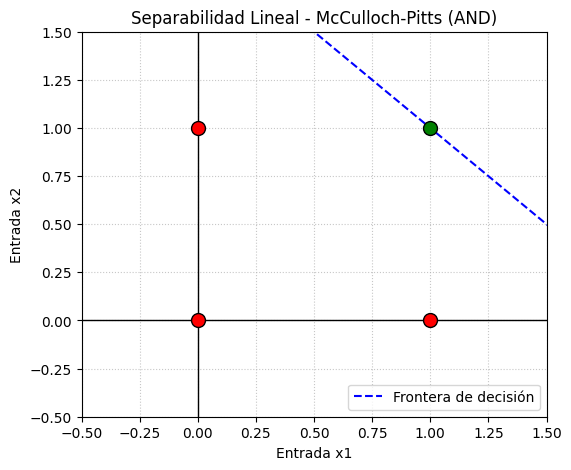

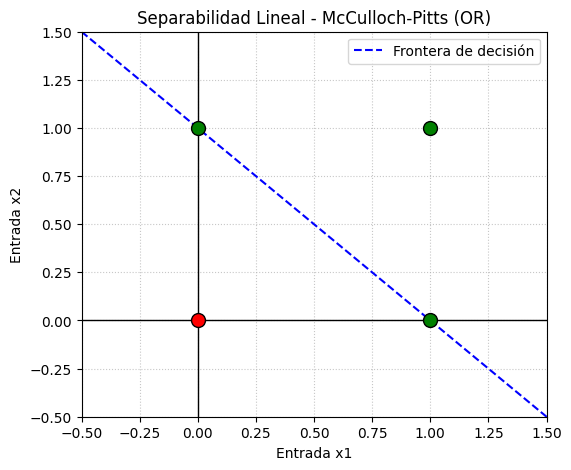

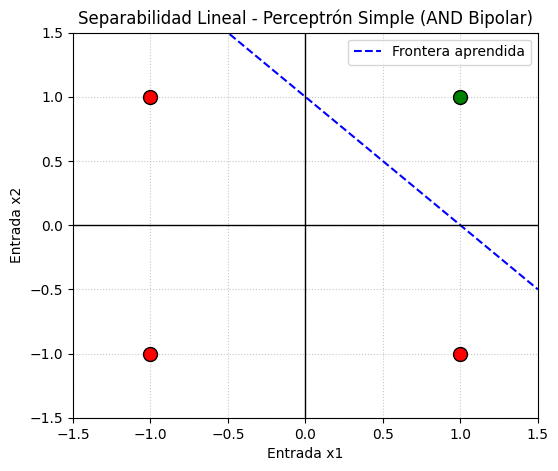

In [ ]:
import matplotlib.pyplot as plt

def graficar_frontera_mp(tipo):
    plt.figure(figsize=(6, 5))

    X = [(0, 0), (0, 1), (1, 0), (1, 1)]

    if tipo == 'AND':
        colores = ['red', 'red', 'red', 'green']
        titulo = "Separabilidad Lineal - McCulloch-Pitts (AND)"
        x1_recta = [-0.5, 2.5]
        x2_recta = [-x + 2 for x in x1_recta]

    elif tipo == 'OR':
        colores = ['red', 'green', 'green', 'green']
        titulo = "Separabilidad Lineal - McCulloch-Pitts (OR)"
        x1_recta = [-0.5, 2.5]
        x2_recta = [-x + 1 for x in x1_recta]

    for i in range(len(X)):
        plt.scatter(X[i][0], X[i][1], color=colores[i], s=100, zorder=5, edgecolors='black')

    plt.plot(x1_recta, x2_recta, color='blue', linestyle='--', label='Frontera de decisión')

    plt.title(titulo)
    plt.xlabel('Entrada x1')
    plt.ylabel('Entrada x2')
    plt.xlim(-0.5, 1.5)
    plt.ylim(-0.5, 1.5)
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.axhline(0, color='black', linewidth=1)
    plt.axvline(0, color='black', linewidth=1)
    plt.legend()
    plt.show()

def graficar_frontera_perceptron(pesos, entradas, salidas_deseadas):
    plt.figure(figsize=(6, 5))

    for i in range(len(entradas)):
        x1, x2 = entradas[i][1], entradas[i][2]
        if salidas_deseadas[i] == 1:
            plt.scatter(x1, x2, color='green', s=100, zorder=5, edgecolors='black')
        else:
            plt.scatter(x1, x2, color='red', s=100, zorder=5, edgecolors='black')

    bias, w1, w2 = pesos[0], pesos[1], pesos[2]

    if w2 != 0:
        x1_recta = [-1.5, 1.5]
        x2_recta = [-(w1/w2)*x - (bias/w2) for x in x1_recta]
        plt.plot(x1_recta, x2_recta, color='blue', linestyle='--', label='Frontera aprendida')

    plt.title("Separabilidad Lineal - Perceptrón Simple (AND Bipolar)")
    plt.xlabel('Entrada x1')
    plt.ylabel('Entrada x2')
    plt.xlim(-1.5, 1.5)
    plt.ylim(-1.5, 1.5)
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.axhline(0, color='black', linewidth=1)
    plt.axvline(0, color='black', linewidth=1)
    plt.legend()
    plt.show()

print("Generando gráficas...")
graficar_frontera_mp('AND')
graficar_frontera_mp('OR')
graficar_frontera_perceptron(pesos, entradas, salidas_deseadas)

# Actividad 02

## Modelo 03: ADALINE

### Configuración de los datos

In [2]:
# Matriz de entradas (Descodificador 3 bits). El primer '1' es el bias.
entradas = [
    [1, 0, 0, 0],
    [1, 0, 0, 1],
    [1, 0, 1, 0],
    [1, 0, 1, 1],
    [1, 1, 0, 0],
    [1, 1, 0, 1],
    [1, 1, 1, 0],
    [1, 1, 1, 1]
]

# Salidas esperadas (valores decimales del 0 al 7)
salidas_deseadas = [0, 1, 2, 3, 4, 5, 6, 7]

# Inicialización de pesos aleatorios entre 0 y 1
random.seed(42) # Semilla para reproducibilidad
pesos = [random.uniform(0, 1) for _ in range(4)]

# Parámetros de entrenamiento
tasa_aprendizaje = 0.05
epocas = 150

### Ciclo de entrenamiento (Adaline y Regla Delta)

In [3]:
# Lista para almacenar la evolución del error
historial_error = []

print("--- Iniciando Entrenamiento ADALINE ---")

for epoca in range(epocas):
    error_cuadratico_total = 0

    for i in range(len(entradas)):
        x = entradas[i]
        d = salidas_deseadas[i]

        # Cálculo de la salida continua/lineal (Suma ponderada)
        y = sum(pesos[j] * x[j] for j in range(len(pesos)))

        # Cálculo del error directo (sin función escalón)
        error = d - y

        # Acumulación del error cuadrático
        error_cuadratico_total += (error ** 2) / 2

        # Actualización de pesos usando la Regla Delta
        for j in range(len(pesos)):
            pesos[j] = pesos[j] + tasa_aprendizaje * error * x[j]

    # Calcular el Error Cuadrático Medio (MSE) de la época
    mse = error_cuadratico_total / len(entradas)
    historial_error.append(mse)

    # Imprimir progreso cada 30 épocas
    if (epoca + 1) % 30 == 0:
        print(f"Época {epoca+1} | Error Cuadrático Medio: {mse:.4f}")

print("\nEntrenamiento completado.")
print("Pesos óptimos encontrados:", [round(p, 4) for p in pesos])

--- Iniciando Entrenamiento ADALINE ---
Época 30 | Error Cuadrático Medio: 0.0295
Época 60 | Error Cuadrático Medio: 0.0010
Época 90 | Error Cuadrático Medio: 0.0000
Época 120 | Error Cuadrático Medio: 0.0000
Época 150 | Error Cuadrático Medio: 0.0000

Entrenamiento completado.
Pesos óptimos encontrados: [0.0005, 3.9997, 1.9997, 0.9997]


### Verificador del codificador

In [4]:
print("--- Prueba de Eficiencia (Descodificador) ---")

for i in range(len(entradas)):
    x = entradas[i]
    d = salidas_deseadas[i]

    # Predicción final con los pesos ajustados
    y_pred = sum(pesos[j] * x[j] for j in range(len(pesos)))

    print(f"Entrada Binaria: {x[1:]} -> Decimal Esperado: {d} | Predicción Red: {y_pred:.2f}")

--- Prueba de Eficiencia (Descodificador) ---
Entrada Binaria: [0, 0, 0] -> Decimal Esperado: 0 | Predicción Red: 0.00
Entrada Binaria: [0, 0, 1] -> Decimal Esperado: 1 | Predicción Red: 1.00
Entrada Binaria: [0, 1, 0] -> Decimal Esperado: 2 | Predicción Red: 2.00
Entrada Binaria: [0, 1, 1] -> Decimal Esperado: 3 | Predicción Red: 3.00
Entrada Binaria: [1, 0, 0] -> Decimal Esperado: 4 | Predicción Red: 4.00
Entrada Binaria: [1, 0, 1] -> Decimal Esperado: 5 | Predicción Red: 5.00
Entrada Binaria: [1, 1, 0] -> Decimal Esperado: 6 | Predicción Red: 6.00
Entrada Binaria: [1, 1, 1] -> Decimal Esperado: 7 | Predicción Red: 7.00


### Representación Gráfica del error

In [ ]:
# Gráfica de la curva de aprendizaje
plt.figure(figsize=(8, 5))
plt.plot(range(1, epocas + 1), historial_error, color='purple', linewidth=2)
plt.title('Evolución del Error Cuadrático Medio - ADALINE')
plt.xlabel('Épocas')
plt.ylabel('Error Cuadrático Medio (MSE)')
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()

# Actividad 03

## Modelo 04: Perceptrón Multicapa

In [ ]:
def sigmoide(x):
    return 1 / (1 + math.exp(-x))

entradas = [[0, 0], [0, 1], [1, 0], [1, 1]]
salidas_deseadas = [0, 1, 1, 0]

w11, w21 = random.uniform(-1, 1), random.uniform(-1, 1)
w12, w22 = random.uniform(-1, 1), random.uniform(-1, 1)
u1, u2 = random.uniform(-1, 1), random.uniform(-1, 1)

w1_out, w2_out = random.uniform(-1, 1), random.uniform(-1, 1)
v = random.uniform(-1, 1)

alpha = 0.5
epocas = 5000

print("--- Entrenando Perceptrón Multicapa (Compuerta XOR) ---")
for epoca in range(epocas):
    error_total = 0

    for i in range(len(entradas)):
        x1, x2 = entradas[i]
        t = salidas_deseadas[i]


        b1 = sigmoide((w11 * x1) + (w21 * x2) + u1)
        b2 = sigmoide((w12 * x1) + (w22 * x2) + u2)

        y = sigmoide((w1_out * b1) + (w2_out * b2) + v)

        error_total += 0.5 * ((t - y) ** 2)

        d_x = (t - y) * y * (1 - y)

        a1_x = d_x * w1_out * b1 * (1 - b1)
        a2_x = d_x * w2_out * b2 * (1 - b2)

        w1_out += alpha * d_x * b1
        w2_out += alpha * d_x * b2
        v += alpha * d_x

        w11 += alpha * a1_x * x1
        w21 += alpha * a1_x * x2
        u1 += alpha * a1_x

        w12 += alpha * a2_x * x1
        w22 += alpha * a2_x * x2
        u2 += alpha * a2_x

    if (epoca + 1) % 1000 == 0:
        print(f"Época {epoca+1} - Error: {error_total:.4f}")

print("\nPrueba de eficiencia (Predicciones XOR):")
for i in range(len(entradas)):
    x1, x2 = entradas[i]
    b1 = sigmoide((w11 * x1) + (w21 * x2) + u1)
    b2 = sigmoide((w12 * x1) + (w22 * x2) + u2)
    y = sigmoide((w1_out * b1) + (w2_out * b2) + v)
    # Redondeamos para ver la clasificación final
    print(f"Entrada: [{x1}, {x2}] -> Esperado: {salidas_deseadas[i]} | Red: {y:.4f} (Clase: {round(y)})")

--- Entrenando Perceptrón Multicapa (Compuerta XOR) ---
Época 1000 - Error: 0.1913
Época 2000 - Error: 0.0076
Época 3000 - Error: 0.0033
Época 4000 - Error: 0.0021
Época 5000 - Error: 0.0015

Prueba de eficiencia (Predicciones XOR):
Entrada: [0, 0] -> Esperado: 0 | Red: 0.0246 (Clase: 0)
Entrada: [0, 1] -> Esperado: 1 | Red: 0.9739 (Clase: 1)
Entrada: [1, 0] -> Esperado: 1 | Red: 0.9738 (Clase: 1)
Entrada: [1, 1] -> Esperado: 0 | Red: 0.0324 (Clase: 0)


# Modelo 05: Red de Hopfield

In [ ]:
patron_original = [1, -1, 1, -1]
num_neuronas = len(patron_original)

pesos = [[0 for _ in range(num_neuronas)] for _ in range(num_neuronas)]

print("--- Entrenando Red de Hopfield (Regla de Hebb) ---")
for i in range(num_neuronas):
    for j in range(num_neuronas):
        if i != j:
            pesos[i][j] = patron_original[i] * patron_original[j]

print("Matriz de pesos almacenada:")
for fila in pesos:
    print(fila)

patron_ruidoso = [-1, -1, 1, -1]
print(f"\nPatrón ruidoso de entrada: {patron_ruidoso}")

patron_recuperado = list(patron_ruidoso)
cambios = True
iteracion = 1

while cambios:
    cambios = False
    for i in range(num_neuronas):
        y_in = sum(pesos[i][j] * patron_recuperado[j] for j in range(num_neuronas))

        nuevo_estado = 1 if y_in > 0 else (-1 if y_in < 0 else patron_recuperado[i])

        if nuevo_estado != patron_recuperado[i]:
            patron_recuperado[i] = nuevo_estado
            cambios = True

    print(f"Iteración {iteracion}: {patron_recuperado}")
    iteracion += 1

print(f"\nPatrón original:   {patron_original}")
print(f"Patrón recuperado: {patron_recuperado}")
print("¡La red ha logrado asociar y corregir el error!")

--- Entrenando Red de Hopfield (Regla de Hebb) ---
Matriz de pesos almacenada:
[0, -1, 1, -1]
[-1, 0, -1, 1]
[1, -1, 0, -1]
[-1, 1, -1, 0]

Patrón ruidoso de entrada: [-1, -1, 1, -1]
Iteración 1: [1, -1, 1, -1]
Iteración 2: [1, -1, 1, -1]

Patrón original:   [1, -1, 1, -1]
Patrón recuperado: [1, -1, 1, -1]
¡La red ha logrado asociar y corregir el error!


# Modelo 06: Algoritmo de Clustering

In [ ]:
puntos = [
    [1.0, 1.0], [1.5, 2.0], [2.0, 1.0],
    [8.0, 8.0], [9.0, 9.0], [8.5, 10.0]
]

K = 2

centroides = [puntos[0].copy(), puntos[1].copy()]

def distancia_euclidiana(p1, p2):
    return math.sqrt((p1[0] - p2[0])**2 + (p1[1] - p2[1])**2)

print("--- Algoritmo No Supervisado: Clustering K-medio ---")
epocas = 10
for epoca in range(epocas):

    clusters = {0: [], 1: []}


    for punto in puntos:
        dist_c0 = distancia_euclidiana(punto, centroides[0])
        dist_c1 = distancia_euclidiana(punto, centroides[1])

        if dist_c0 < dist_c1:
            clusters[0].append(punto)
        else:
            clusters[1].append(punto)


    centroides_antiguos = [c.copy() for c in centroides]

    for i in range(K):
        if len(clusters[i]) > 0:
            promedio_x = sum(p[0] for p in clusters[i]) / len(clusters[i])
            promedio_y = sum(p[1] for p in clusters[i]) / len(clusters[i])
            centroides[i] = [promedio_x, promedio_y]


    if centroides == centroides_antiguos:
        print(f"El agrupamiento convergió en la iteración {epoca+1}")
        break

print("\nResultados del Clustering:")
for i in range(K):
    print(f"Clúster {i} (Centroide en {centroides[i]}):")
    for p in clusters[i]:
        print(f"  -> Punto {p}")

--- Algoritmo No Supervisado: Clustering K-medio ---
El agrupamiento convergió en la iteración 3

Resultados del Clustering:
Clúster 0 (Centroide en [1.5, 1.3333333333333333]):
  -> Punto [1.0, 1.0]
  -> Punto [1.5, 2.0]
  -> Punto [2.0, 1.0]
Clúster 1 (Centroide en [8.5, 9.0]):
  -> Punto [8.0, 8.0]
  -> Punto [9.0, 9.0]
  -> Punto [8.5, 10.0]


# Modelo 07: Clasificador de K-vecinos más cercano

In [ ]:
def distancia_euclidiana(v1, v2):
    return math.sqrt(sum((v1[i] - v2[i])**2 for i in range(len(v1))))

datos_entrenamiento = [
    ([1.0, 2.0], 'Clase A'), ([1.5, 1.8], 'Clase A'), ([2.0, 2.1], 'Clase A'),
    ([8.0, 8.0], 'Clase B'), ([8.5, 9.0], 'Clase B'), ([9.0, 8.2], 'Clase B')
]

def predecir_knn(nuevo_punto, datos, k=3):
    distancias = []
    for punto, clase in datos:
        dist = distancia_euclidiana(nuevo_punto, punto)
        distancias.append((dist, clase))

    distancias.sort(key=lambda x: x[0])
    k_vecinos = distancias[:k]

    conteo_clases = {}
    for _, clase in k_vecinos:
        conteo_clases[clase] = conteo_clases.get(clase, 0) + 1

    clase_ganadora = max(conteo_clases, key=conteo_clases.get)
    return clase_ganadora, k_vecinos

print("--- Probando Clasificador K-Vecinos Más Cercano (KNN) ---")
puntos_prueba = [[1.2, 1.9], [8.7, 8.5], [5.0, 5.0]]
K = 3

for punto in puntos_prueba:
    clase_pred, vecinos = predecir_knn(punto, datos_entrenamiento, k=K)
    print(f"\nPunto a clasificar: {punto}")
    print(f"Predicción: {clase_pred}")
    print("Distancia a sus 3 vecinos más cercanos:")
    for dist, clase in vecinos:
        print(f"  -> {dist:.2f} (Pertenece a {clase})")

--- Probando Clasificador K-Vecinos Más Cercano (KNN) ---

Punto a clasificar: [1.2, 1.9]
Predicción: Clase A
Distancia a sus 3 vecinos más cercanos:
  -> 0.22 (Pertenece a Clase A)
  -> 0.32 (Pertenece a Clase A)
  -> 0.82 (Pertenece a Clase A)

Punto a clasificar: [8.7, 8.5]
Predicción: Clase B
Distancia a sus 3 vecinos más cercanos:
  -> 0.42 (Pertenece a Clase B)
  -> 0.54 (Pertenece a Clase B)
  -> 0.86 (Pertenece a Clase B)

Punto a clasificar: [5.0, 5.0]
Predicción: Clase A
Distancia a sus 3 vecinos más cercanos:
  -> 4.17 (Pertenece a Clase A)
  -> 4.24 (Pertenece a Clase B)
  -> 4.74 (Pertenece a Clase A)


# Modelo 08: Mapas de Kohonen

In [ ]:
datos_entrada = [
    [1.0, 0.0, 0.0], [0.9, 0.1, 0.0],
    [0.0, 0.0, 1.0], [0.0, 0.1, 0.9],
    [0.1, 0.1, 0.1], [0.2, 0.2, 0.2]
]

neuronas = [[random.uniform(0, 1) for _ in range(3)] for _ in range(3)]

tasa_aprendizaje = 0.5
epocas = 100

print("--- Entrenando Mapa de Kohonen ---")
for epoca in range(epocas):
    for x in datos_entrada:


        distancias = []
        for i, w in enumerate(neuronas):

            dist = math.sqrt(sum((x[d] - w[d])**2 for d in range(3)))
            distancias.append(dist)

        indice_ganadora = distancias.index(min(distancias))

        for d in range(3):
            neuronas[indice_ganadora][d] += tasa_aprendizaje * (x[d] - neuronas[indice_ganadora][d])

    tasa_aprendizaje *= 0.95

print("\nPesos finales de las neuronas (Centroides descubiertos):")
for i, w in enumerate(neuronas):
    print(f"Neurona {i}: {[round(val, 2) for val in w]}")

print("\nPrueba de eficiencia (Asignación de categorías):")
for x in datos_entrada:
    distancias = [math.sqrt(sum((x[d] - w[d])**2 for d in range(3))) for w in neuronas]
    ganadora = distancias.index(min(distancias))
    print(f"Color de entrada {x} -> Clasificado en Neurona {ganadora}")

--- Entrenando Mapa de Kohonen ---

Pesos finales de las neuronas (Centroides descubiertos):
Neurona 0: [0.95, 0.05, 0.0]
Neurona 1: [0.08, 0.1, 0.54]
Neurona 2: [0.75, 1.0, 0.41]

Prueba de eficiencia (Asignación de categorías):
Color de entrada [1.0, 0.0, 0.0] -> Clasificado en Neurona 0
Color de entrada [0.9, 0.1, 0.0] -> Clasificado en Neurona 0
Color de entrada [0.0, 0.0, 1.0] -> Clasificado en Neurona 1
Color de entrada [0.0, 0.1, 0.9] -> Clasificado en Neurona 1
Color de entrada [0.1, 0.1, 0.1] -> Clasificado en Neurona 1
Color de entrada [0.2, 0.2, 0.2] -> Clasificado en Neurona 1


# Modelo 09: Red de Hamming

In [ ]:
clase_A = [1, -1, 1, -1]
clase_B = [-1, 1, -1, 1]
clase_C = [1, 1, 1, 1]
prototipos = [clase_A, clase_B, clase_C]
nombres_clases = ["Clase A", "Clase B", "Clase C"]

pesos_feedforward = [[p / 2 for p in prototipo] for prototipo in prototipos]
sesgo = len(clase_A) / 2

def predecir_hamming(patron_entrada):
    activaciones = []
    for pesos_neurona in pesos_feedforward:
        y_in = sum(w * x for w, x in zip(pesos_neurona, patron_entrada)) + sesgo
        activaciones.append(y_in)

    indice_ganador = activaciones.index(max(activaciones))
    return nombres_clases[indice_ganador], activaciones

print("--- Prueba de la Red de Hamming ---")
patron_ruidoso = [1, 1, 1, -1]

print(f"Patrones almacenados:")
print(f"A: {clase_A}\nB: {clase_B}\nC: {clase_C}")
print(f"\nEvaluando patrón ruidoso: {patron_ruidoso}")

prediccion, niveles_activacion = predecir_hamming(patron_ruidoso)

print("\nNiveles de activación de cada neurona (a mayor valor, menos distancia Hamming):")
for nombre, activacion in zip(nombres_clases, niveles_activacion):
    print(f"  -> Neurona {nombre}: {activacion}")

print(f"\nEl clasificador de Hamming determinó que el patrón pertenece a la: {prediccion}")

--- Prueba de la Red de Hamming ---
Patrones almacenados:
A: [1, -1, 1, -1]
B: [-1, 1, -1, 1]
C: [1, 1, 1, 1]

Evaluando patrón ruidoso: [1, 1, 1, -1]

Niveles de activación de cada neurona (a mayor valor, menos distancia Hamming):
  -> Neurona Clase A: 3.0
  -> Neurona Clase B: 1.0
  -> Neurona Clase C: 3.0

El clasificador de Hamming determinó que el patrón pertenece a la: Clase A


# Modelo 10: Matriz Memoria Asociativa

In [ ]:
entradas = [
    [1, 0, 0],
    [0, 1, 0]
]
salidas_asociadas = [
    [1, 0],
    [0, 1]
]

num_entradas = len(entradas[0])
num_salidas = len(salidas_asociadas[0])

pesos = [[0 for _ in range(num_entradas)] for _ in range(num_salidas)]

print("--- Entrenando Matriz Memoria Asociativa ---")
for p in range(len(entradas)):
    x = entradas[p]
    y = salidas_asociadas[p]
    for i in range(num_salidas):
        for j in range(num_entradas):

            if y[i] == 1 and x[j] == 1:
                pesos[i][j] = 1

print("Matriz de memoria generada:")
for fila in pesos:
    print(fila)

def recuperar_memoria(patron_prueba):
    salida = [0 for _ in range(num_salidas)]
    for i in range(num_salidas):

        suma = sum(pesos[i][j] * patron_prueba[j] for j in range(num_entradas))

        salida[i] = 1 if suma > 0 else 0
    return salida

print("\nPrueba de recuperación:")
print(f"Entrada {entradas[0]} -> Recuperado: {recuperar_memoria(entradas[0])} (Esperado: {salidas_asociadas[0]})")

patron_ruidoso = [0, 1, 1]
print(f"Entrada ruidosa {patron_ruidoso} -> Recuperado: {recuperar_memoria(patron_ruidoso)} (Esperado: {salidas_asociadas[1]})")

--- Entrenando Matriz Memoria Asociativa ---
Matriz de memoria generada:
[1, 0, 0]
[0, 1, 0]

Prueba de recuperación:
Entrada [1, 0, 0] -> Recuperado: [1, 0] (Esperado: [1, 0])
Entrada ruidosa [0, 1, 1] -> Recuperado: [0, 1] (Esperado: [0, 1])


# Modelo 11: Clasificador Carpenter / Grossberg

In [ ]:
datos_entrada = [
    [1, 1, 0, 0, 0],
    [1, 0, 0, 0, 0],
    [0, 0, 1, 1, 0],
    [0, 0, 1, 1, 1]
]

vigilancia = 0.6
categorias = []

def calcular_similitud(patron, categoria):

    interseccion = sum(1 for p, c in zip(patron, categoria) if p == 1 and c == 1)

    norma_patron = sum(patron)
    if norma_patron == 0: return 0
    return interseccion / norma_patron

print("--- Ejecutando Clasificador Carpenter/Grossberg (ART-1) ---")
for i, patron in enumerate(datos_entrada):
    agrupado = False


    for j, categoria in enumerate(categorias):
        similitud = calcular_similitud(patron, categoria)

        if similitud >= vigilancia:
            print(f"Patrón {i} {patron} -> Asignado a Categoría {j} (Similitud: {similitud:.2f})")
            categorias[j] = [1 if p == 1 and c == 1 else 0 for p, c in zip(patron, categoria)]
            agrupado = True
            break

    if not agrupado:
        print(f"Patrón {i} {patron} -> ¡Nueva Categoría Creada! (Categoría {len(categorias)})")
        categorias.append(patron.copy())

print("\nPrototipos finales de las categorías descubiertas:")
for j, categoria in enumerate(categorias):
    print(f"Categoría {j}: {categoria}")

--- Ejecutando Clasificador Carpenter/Grossberg (ART-1) ---
Patrón 0 [1, 1, 0, 0, 0] -> ¡Nueva Categoría Creada! (Categoría 0)
Patrón 1 [1, 0, 0, 0, 0] -> Asignado a Categoría 0 (Similitud: 1.00)
Patrón 2 [0, 0, 1, 1, 0] -> ¡Nueva Categoría Creada! (Categoría 1)
Patrón 3 [0, 0, 1, 1, 1] -> Asignado a Categoría 1 (Similitud: 0.67)

Prototipos finales de las categorías descubiertas:
Categoría 0: [1, 0, 0, 0, 0]
Categoría 1: [0, 0, 1, 1, 0]


# Modelo 12: Clasificador Gausiano

In [ ]:


datos = [
    ([20.0, 0.5], 0), ([25.0, 0.6], 0), ([15.0, 0.4], 0),
    ([400.0, 1.6], 1), ([450.0, 1.8], 1), ([380.0, 1.5], 1)
]

estadisticas_clases = {}

for clase in [0, 1]:
    muestras = [d[0] for d in datos if d[1] == clase]
    num_caracteristicas = len(muestras[0])

    estadisticas_clases[clase] = []

    for i in range(num_caracteristicas):
        valores = [m[i] for m in muestras]
        media = sum(valores) / len(valores)
        varianza = sum((v - media)**2 for v in valores) / len(valores)
        varianza = max(varianza, 1e-6)

        estadisticas_clases[clase].append((media, varianza))

def densidad_gaussiana(x, media, varianza):
    exponente = math.exp(-((x - media)**2) / (2 * varianza))
    return (1 / math.sqrt(2 * math.pi * varianza)) * exponente

def predecir_gaussiano(nuevo_dato):
    probabilidades = {}

    for clase, stats in estadisticas_clases.items():
        probabilidad_clase = 1.0

        for i in range(len(nuevo_dato)):
            media, varianza = stats[i]
            prob = densidad_gaussiana(nuevo_dato[i], media, varianza)
            probabilidad_clase *= prob

        probabilidades[clase] = probabilidad_clase

    clase_predicha = max(probabilidades, key=probabilidades.get)
    return clase_predicha, probabilidades

print("--- Prueba del Clasificador Gausiano ---")
print("Estadísticas calculadas (Media, Varianza) por clase:")
for clase, stats in estadisticas_clases.items():
    nombre = "Perros" if clase == 0 else "Caballos"
    print(f"{nombre}: Peso={stats[0]}, Altura={stats[1]}")

nuevo_animal = [22.0, 0.55]
prediccion, probs = predecir_gaussiano(nuevo_animal)
nombre_prediccion = "Perro" if prediccion == 0 else "Caballo"

print(f"\nEvaluando nuevo dato (Peso: {nuevo_animal[0]}, Altura: {nuevo_animal[1]}):")
print(f"Probabilidades brutas: {probs}")
print(f"El clasificador Gausiano predice que es un: {nombre_prediccion}")

--- Prueba del Clasificador Gausiano ---
Estadísticas calculadas (Media, Varianza) por clase:
Perros: Peso=(20.0, 16.666666666666668), Altura=(0.5, 0.006666666666666664)
Caballos: Peso=(410.0, 866.6666666666666), Altura=(1.6333333333333335, 0.015555555555555559)

Evaluando nuevo dato (Peso: 22.0, Altura: 0.55):
Probabilidades brutas: {0: 0.35107170882304745, 1: 3.423651468713596e-56}
El clasificador Gausiano predice que es un: Perro


# Modelo 13: Clasificador Óptimo

In [ ]:

datos_entrenamiento = [
    ([1, 1, 0], 'Clase X'),
    ([1, 0, 0], 'Clase X'),
    ([1, 1, 0], 'Clase X'),
    ([0, 0, 0], 'Clase X'),
    ([1, 1, 1], 'Clase Y'),
    ([0, 1, 1], 'Clase Y'),
    ([1, 0, 1], 'Clase Y')
]


total_datos = len(datos_entrenamiento)
clases = list(set([d[1] for d in datos_entrenamiento]))
num_caracteristicas = len(datos_entrenamiento[0][0])

probabilidades_priori = {}
probabilidades_condicionales = {}

for clase in clases:
    datos_clase = [d[0] for d in datos_entrenamiento if d[1] == clase]
    total_clase = len(datos_clase)

    probabilidades_priori[clase] = total_clase / total_datos

    prob_condicional = []
    for i in range(num_caracteristicas):
        casos_positivos = sum(1 for d in datos_clase if d[i] == 1)
        prob = (casos_positivos + 1) / (total_clase + 2)
        prob_condicional.append(prob)

    probabilidades_condicionales[clase] = prob_condicional

def predecir_optimo(nuevo_patron):
    probabilidades_finales = {}

    for clase in clases:
        prob_acumulada = probabilidades_priori[clase]

        for i in range(num_caracteristicas):
            prob_bit_1 = probabilidades_condicionales[clase][i]

            if nuevo_patron[i] == 1:
                prob_acumulada *= prob_bit_1
            else:
                prob_acumulada *= (1 - prob_bit_1)

        probabilidades_finales[clase] = prob_acumulada

    clase_predicha = max(probabilidades_finales, key=probabilidades_finales.get)
    return clase_predicha, probabilidades_finales

print("--- Entrenando Clasificador Óptimo (Probabilidades) ---")
for clase in clases:
    print(f"Probabilidad a priori de {clase}: {probabilidades_priori[clase]:.2f}")
    print(f"Probabilidad condicional de bits para {clase}: {[round(p, 2) for p in probabilidades_condicionales[clase]]}")

patron_prueba = [0, 1, 0]
prediccion, probs = predecir_optimo(patron_prueba)

print(f"\nEvaluando nuevo patrón binario: {patron_prueba}")
for clase, prob in probs.items():
    print(f" -> Probabilidad de pertenecer a {clase}: {prob:.4f}")
print(f"\nEl Clasificador Óptimo asigna el patrón a la: {prediccion}")

--- Entrenando Clasificador Óptimo (Probabilidades) ---
Probabilidad a priori de Clase Y: 0.43
Probabilidad condicional de bits para Clase Y: [0.6, 0.6, 0.8]
Probabilidad a priori de Clase X: 0.57
Probabilidad condicional de bits para Clase X: [0.67, 0.5, 0.17]

Evaluando nuevo patrón binario: [0, 1, 0]
 -> Probabilidad de pertenecer a Clase Y: 0.0206
 -> Probabilidad de pertenecer a Clase X: 0.0794

El Clasificador Óptimo asigna el patrón a la: Clase X
